# Multi-class Classification Metrics (Iris, TensorFlow)
Three classes, so precision/recall/F1 need an **averaging** strategy (`macro` = unweighted mean over classes)
and the ROC curve is drawn **one-vs-rest** (one curve per class).

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, roc_curve, auc, roc_auc_score)

keras.utils.set_random_seed(42)

iris = load_iris()
X = iris.data
y = iris.target
class_names = iris.target_names
n_classes = len(class_names)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [2]:
# Define the model (softmax output = one probability per class)
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(n_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',  # integer labels 0,1,2
              metrics=['accuracy'])

# Iris is tiny (96 training rows), so it needs more epochs than a large dataset
history = model.fit(X_train, y_train, epochs=100, batch_size=16, validation_split=0.2, verbose=0)
print(f"Final validation accuracy: {history.history['val_accuracy'][-1]:.3f}")

Final validation accuracy: 1.000


In [3]:
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)  # highest-probability class

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (macro): {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall (macro): {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1-score (macro): {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"ROC AUC (one-vs-rest, macro): {roc_auc_score(y_test, y_pred_probs, multi_class='ovr'):.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test, y_pred, target_names=class_names)}")

Accuracy: 0.9667
Precision (macro): 0.9697
Recall (macro): 0.9667
F1-score (macro): 0.9666
ROC AUC (one-vs-rest, macro): 0.9967
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



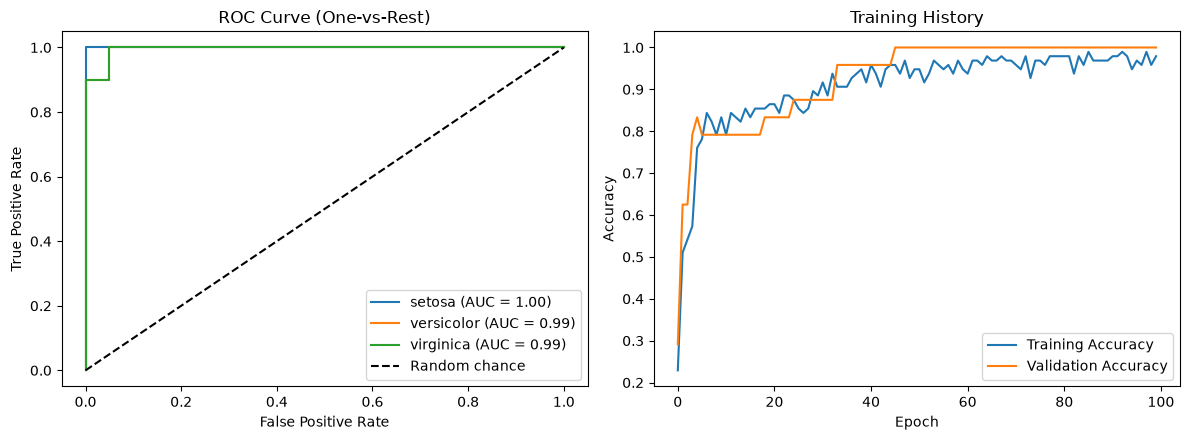

In [4]:
# --- ROC Curve (one-vs-rest): treat each class as "positive" vs. the other two ---
y_test_bin = label_binarize(y_test, classes=range(n_classes))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    ax1.plot(fpr, tpr, label=f'{class_names[i]} (AUC = {auc(fpr, tpr):.2f})')
ax1.plot([0, 1], [0, 1], 'k--', label='Random chance')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve (One-vs-Rest)')
ax1.legend(loc="lower right")

ax2.plot(history.history['accuracy'], label='Training Accuracy')
ax2.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Training History')
ax2.legend()
plt.tight_layout()
plt.show()